# Support Vector Regression: Kernel Methods and Hyperparameter Tuning

Comprehensive guide to SVM regression including different kernels, parameter tuning, and performance analysis.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Generate non-linear regression data
np.random.seed(42)
X = np.sort(np.random.uniform(0, 10, 200)).reshape(-1, 1)
y = np.sin(X).ravel() * X.ravel() + np.random.randn(200) * 0.5

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Compare different kernels
kernels = ['linear', 'rbf', 'poly']
colors = ['blue', 'green', 'red']
predictions = {}

plt.figure(figsize=(15, 4))

for idx, (kernel, color) in enumerate(zip(kernels, colors)):
    svr = SVR(kernel=kernel, C=100, epsilon=0.1)
    svr.fit(X_train, y_train)
    
    y_pred = svr.predict(X_test)
    predictions[kernel] = y_pred
    
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    
    plt.subplot(1, 3, idx + 1)
    X_plot = np.linspace(0, 10, 300).reshape(-1, 1)
    y_plot = svr.predict(X_plot)
    
    plt.scatter(X_train, y_train, alpha=0.5, label='Train')
    plt.scatter(X_test, y_test, alpha=0.5, label='Test')
    plt.plot(X_plot, y_plot, color=color, linewidth=2, label=f'{kernel.upper()} (R²={r2:.3f})')
    plt.xlabel('X')
    plt.ylabel('y')
    plt.title(f'{kernel.upper()} Kernel SVM')
    plt.legend()
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Hyperparameter tuning for RBF kernel
param_grid = {
    'C': [0.1, 1, 10, 100],
    'epsilon': [0.01, 0.1, 0.5],
    'gamma': ['scale', 'auto']
}

svr = SVR(kernel='rbf')
grid_search = GridSearchCV(svr, param_grid, cv=5, scoring='r2', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best Parameters for RBF SVR:")
print(grid_search.best_params_)
print(f"Best CV R² Score: {grid_search.best_score_:.4f}")

best_svr = grid_search.best_estimator_
y_pred_best = best_svr.predict(X_test)
print(f"Test R² Score: {r2_score(y_test, y_pred_best):.4f}")
print(f"Test MAE: {mean_absolute_error(y_test, y_pred_best):.4f}")

# 🌸 SVM Example: Binary Classification on Iris Dataset

This notebook demonstrates how Support Vector Machines (SVMs) work using the Iris dataset. We'll:
- Load and preprocess data
- Train an SVM with RBF kernel
- Visualize decision boundary and support vectors
- Compare different kernels

**Author**: AI Assistant
**Date**: 2024


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.svm import SVC
import pandas as pd
plt.style.use('ggplot')
%matplotlib inline

## 1. Load and Prepare Data

We use only the first two features (sepal length, sepal width) and two classes (setosa, versicolor).

In [19]:
# Load iris dataset
iris = datasets.load_iris()
# pandas df iris

df = pd.DataFrame(data= np.c_[iris['data'], iris['target']],
                     columns= iris['feature_names'] + ['target'])
df.head()
df['sepal width (cm)'].max()

4.4

In [ ]:

iris.data.shape, iris.target.shape
X = iris.data[:, :2]  # First two features: sepal length, sepal width
y = iris.target       # All three classes

# Keep only classes 0 (setosa) and 1 (versicolor)
X = X[y != 2]
y = y[y != 2]

print(f"Shape of X: {X.shape}")
print(f"Unique classes: {np.unique(y)}")

## 2. Train SVM Classifier

In [3]:
# Create SVM with RBF kernel
svm_clf = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)

# Fit the model
svm_clf.fit(X, y)

print(f"Number of support vectors: {len(svm_clf.support_vectors_)}")

Number of support vectors: 25


## 3. Plot Decision Boundary with Support Vectors

In [4]:
def plot_decision_boundary(X, y, model, title="SVM Decision Boundary", show_sv=True):
    h = 0.02  # Step size in mesh
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.RdYlBu)
    scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu, edgecolors='black')
    
    if show_sv:
        sv = model.support_vectors_
        plt.scatter(sv[:, 0], sv[:, 1], s=100, facecolors='none', edgecolors='red', linewidth=2, label='Support Vectors')
        plt.legend()
    
    plt.title(title)
    plt.xlabel('Sepal Length (cm)')
    plt.ylabel('Sepal Width (cm)')
    plt.colorbar(scatter)
    plt.show()

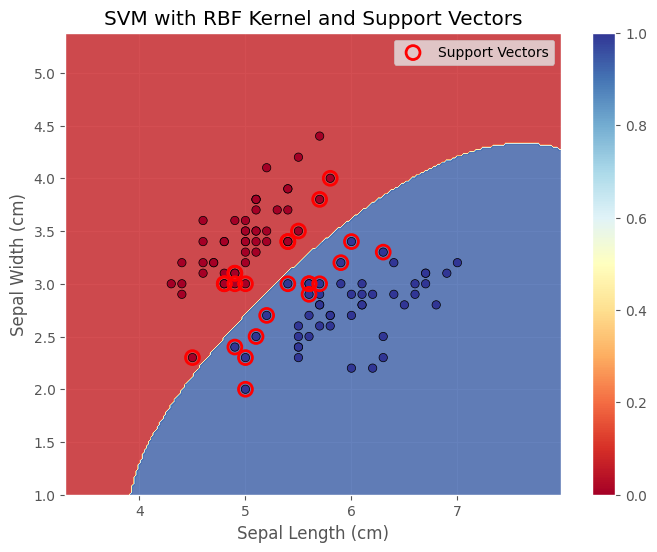

In [5]:
# Plot decision boundary with support vectors
plot_decision_boundary(X, y, svm_clf, "SVM with RBF Kernel and Support Vectors", show_sv=True)

## 4. Compare Different Kernels

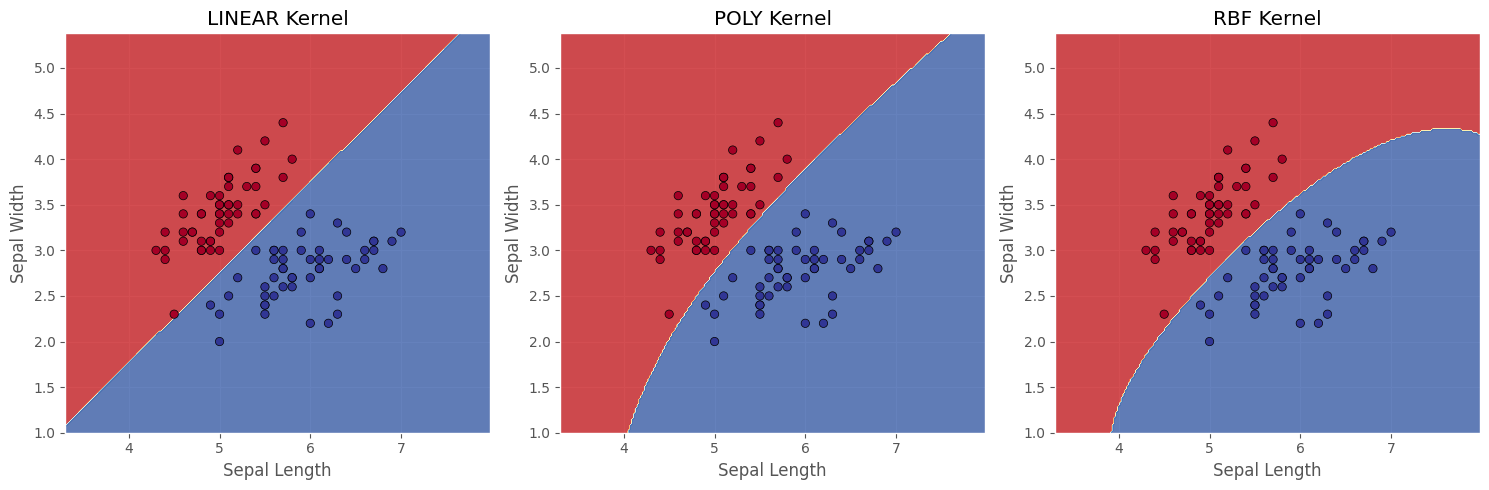

In [6]:
kernels = ['linear', 'poly', 'rbf']
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, kernel in enumerate(kernels):
    clf = SVC(kernel=kernel, C=1.0, gamma='scale', random_state=42)
    clf.fit(X, y)
    
    h = 0.02
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    ax = axes[i]
    ax.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.RdYlBu)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu, edgecolors='black')
    ax.set_title(f'{kernel.upper()} Kernel')
    ax.set_xlabel('Sepal Length')
    ax.set_ylabel('Sepal Width')

plt.tight_layout()
plt.show()

## 5. Bonus: Explore Margin with Different C Values

Lower C → wider margin, more misclassifications
Higher C → narrower margin, fewer misclassifications

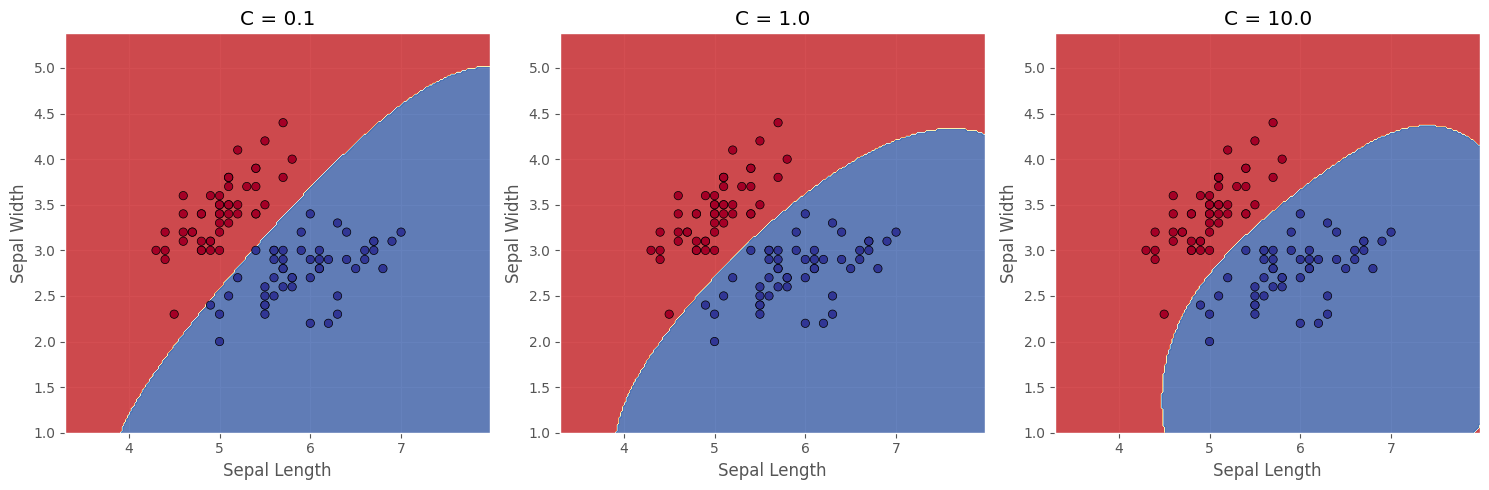

In [7]:
C_values = [0.1, 1.0, 10.0]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, C in enumerate(C_values):
    clf = SVC(kernel='rbf', C=C, gamma='scale', random_state=42)
    clf.fit(X, y)
    
    h = 0.02
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    ax = axes[i]
    ax.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.RdYlBu)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu, edgecolors='black')
    ax.set_title(f'C = {C}')
    ax.set_xlabel('Sepal Length')
    ax.set_ylabel('Sepal Width')

plt.tight_layout()
plt.show()

## ✅ Summary

- SVM finds the **optimal separating hyperplane** with maximum margin.
- Only **support vectors** matter — others are ignored.
- **RBF kernel** handles non-linear boundaries well.
- **C parameter** controls trade-off between margin width and classification accuracy.

This is why SVMs are powerful even with small datasets!